# Step 1: Data Preparation and SQL Retrieval 

**FMCG Demand Planning and Forecasting: Capstone Project**

What we hope to achieve:

1. Load the data and take a first look
2. Store it in a SQL database and run some queries
3. Check the data quality (missing values, duplicates, labels)
4. Merge the sales data with a promotional calendar.
5. Save the cleaned data for the next step.

### 1. Load the data

In [1]:
# Importing libraries
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read the CSV file into a df
fmcg_df = pd.read_csv("data/fmcg_sales_3years_1M_rows.csv")
print(fmcg_df.shape)

(1100000, 33)


In [3]:
#Print the first 5 rows
fmcg_df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [4]:
#Check the columns and data types
fmcg_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   date            1100000 non-null  str    
 1   year            1100000 non-null  int64  
 2   month           1100000 non-null  int64  
 3   day             1100000 non-null  int64  
 4   weekofyear      1100000 non-null  int64  
 5   weekday         1100000 non-null  int64  
 6   is_weekend      1100000 non-null  int64  
 7   is_holiday      1100000 non-null  int64  
 8   temperature     1100000 non-null  float64
 9   rain_mm         1100000 non-null  float64
 10  store_id        1100000 non-null  str    
 11  country         1100000 non-null  str    
 12  city            1100000 non-null  str    
 13  channel         1100000 non-null  str    
 14  latitude        1100000 non-null  float64
 15  longitude       1100000 non-null  float64
 16  sku_id          1100000 non-null  str    
 17  

In [5]:
# The date column was read as text, so I convert it to a proper date format
fmcg_df["date"] = pd.to_datetime(fmcg_df["date"])

#Check the time period covered
print("First date:", fmcg_df["date"].min())
print("Last date:", fmcg_df["date"].max())

First date: 2021-01-01 00:00:00
Last date: 2023-12-31 00:00:00


In [6]:
# How many different stores, SKUs, cities, countries and channels?
print("Stores   :", fmcg_df["store_id"].nunique())
print("SKUs     :", fmcg_df["sku_id"].nunique())
print("Cities   :", fmcg_df["city"].nunique())
print("Countries:", fmcg_df["country"].nunique())
print("Channels :", fmcg_df["channel"].nunique())

Stores   : 13
SKUs     : 102
Cities   : 9
Countries: 7
Channels : 4


### 2. SQL retrieval

The 1.1M rows are big, so I saved them in a SQLite database and use SQL to pull out only what I need.

In [7]:
# Create the data folder if it doesn't exist
os.makedirs("data", exist_ok=True)

# Create a database file and save the DataFrame as a table called "sales"
conn = sqlite3.connect("data/fmcg.db")
fmcg_df.to_sql("sales", conn, if_exists="replace", index=False)

1100000

In [8]:
# Query 1: how many rows and what dates are in the table?
query = """
SELECT COUNT(*) AS total_rows,
       MIN(date) AS first_date,
       MAX(date) AS last_date
FROM sales
"""
pd.read_sql(query, conn)

,total_rows,first_date,last_date
0,1100000,2021-01-01 00:00:00,2023-12-31 00:00:00


In [9]:
# Query 2: WHERE filter - only select the columns I need, for 2023 only
query = """
SELECT date, sku_id, units_sold, list_price, channel
FROM sales
WHERE date >= '2023-01-01'
"""
sales_2023 = pd.read_sql(query, conn)
print(sales_2023.shape)
sales_2023.head()

(366460, 5)


,date,sku_id,units_sold,list_price,channel
0,2023-01-01 00:00:00,SKU0086,14,10.49,Hypermarket
1,2023-01-02 00:00:00,SKU0086,11,10.49,Hypermarket
2,2023-01-03 00:00:00,SKU0086,9,10.49,Hypermarket
3,2023-01-04 00:00:00,SKU0086,8,10.49,Hypermarket
4,2023-01-05 00:00:00,SKU0086,11,10.49,Hypermarket


In [10]:
# Query 3: GROUP BY - total units and net sales for each country
query = """
SELECT country,
       SUM(units_sold) AS total_units,
       SUM(net_sales) AS total_net_sales
FROM sales
GROUP BY country
ORDER BY total_net_sales DESC
"""
pd.read_sql(query, conn)

,country,total_units,total_net_sales
0,Italy,19361774,1.371931e+08
1,Spain,14668017,1.067048e+08
2,Germany,11738571,8.852556e+07
3,Austria,5742174,4.302003e+07
4,France,6014974,4.260161e+07
5,Poland,5860180,4.238526e+07
6,Netherlands,1730292,1.251615e+07


In [11]:
# Query 4: JOIN - first make a small table with one row per store
stores = fmcg_df[["store_id", "city", "latitude", "longitude"]].drop_duplicates()
stores.to_sql("stores", conn, if_exists="replace", index=False)

# Join the sales table with the stores table and total the sales for each city
query = """
SELECT st.city,
       SUM(sa.net_sales) AS total_net_sales
FROM sales AS sa
JOIN stores AS st ON sa.store_id = st.store_id
GROUP BY st.city
ORDER BY total_net_sales DESC
"""
pd.read_sql(query, conn)

,city,total_net_sales
0,Berlin,88525559.01
1,Rome,72437522.63
2,Barcelona,67739349.27
3,Milan,64755553.49
4,Vienna,43020025.97
5,Paris,42601612.57
6,Warsaw,42385262.52
7,Madrid,38965417.77
8,Amsterdam,12516149.60


### 3. Data cleaning

In [12]:
# Missing values in each column
fmcg_df.isnull().sum()

date              0
year              0
month             0
day               0
weekofyear        0
weekday           0
is_weekend        0
is_holiday        0
temperature       0
rain_mm           0
store_id          0
country           0
city              0
channel           0
latitude          0
longitude         0
sku_id            0
sku_name          0
category          0
subcategory       0
brand             0
units_sold        0
list_price        0
discount_pct      0
promo_flag        0
gross_sales       0
net_sales         0
stock_on_hand     0
stock_out_flag    0
lead_time_days    0
supplier_id       0
purchase_cost     0
margin_pct        0
dtype: int64

In [13]:
# Duplicate rows
# 1) Rows that are completely identical
print("Identical rows:", fmcg_df.duplicated().sum())

# 2) Rows with the same store, SKU and date
print("Same store + SKU + date:", fmcg_df.duplicated(subset=["store_id", "sku_id", "date"]).sum())

# 3) The key suggested in the project guide: SKU + date + channel + city
print("Same SKU + date + channel + city:", fmcg_df.duplicated(subset=["sku_id", "date", "channel", "city"]).sum())

Identical rows: 0
Same store + SKU + date: 0
Same SKU + date + channel + city: 67890


In [14]:
# Why does the guide's key show duplicates? Look at stores that share the same city and channel
store_counts = fmcg_df.groupby(["city", "channel"])["store_id"].nunique()
print(store_counts)

city       channel    
Amsterdam  Convenience    1
Barcelona  E-commerce     1
           Supermarket    1
Berlin     Hypermarket    2
Madrid     E-commerce     1
Milan      E-commerce     1
           Supermarket    1
Paris      Hypermarket    1
Rome       Hypermarket    1
           Supermarket    1
Vienna     Hypermarket    1
Warsaw     Hypermarket    1
Name: store_id, dtype: int64


Berlin has **two hypermarkets** (two different stores), so their rows look like duplicates on the data's key but they are real, separate sales. Each row is unique by store + SKU + date.

In [15]:
# Check the category labels for spelling or spacing problems
for col in ["country", "city", "channel", "category"]:
    print(fmcg_df[col].value_counts())
    print()

country
Italy          350400
Spain          262800
Germany        175200
Poland          87600
France          87600
Austria         87600
Netherlands     48800
Name: count, dtype: int64

city
Berlin       175200
Rome         175200
Milan        175200
Barcelona    175200
Warsaw        87600
Paris         87600
Vienna        87600
Madrid        87600
Amsterdam     48800
Name: count, dtype: int64

channel
Hypermarket    525600
Supermarket    262800
E-commerce     262800
Convenience     48800
Name: count, dtype: int64

category
Beverages        266085
Snacks           261705
Personal Care    199290
Dairy            196005
Home Care        176915
Name: count, dtype: int64



In [16]:
# Check that gross sales = units sold x list price
# (the biggest difference should be tiny, just rounding)
difference = (fmcg_df["gross_sales"] - fmcg_df["units_sold"] * fmcg_df["list_price"]).abs()
print("Biggest difference:", difference.max())

Biggest difference: 9.094947017729282e-13


In [17]:
# Zero-sales days and stockout days
print("Days with zero units sold:", (fmcg_df["units_sold"] == 0).sum())
print("Stockout days:", fmcg_df["stock_out_flag"].sum())
print("Stockout rate:", round(fmcg_df["stock_out_flag"].mean() * 100, 1), "%")

Days with zero units sold: 3092
Stockout days: 33114
Stockout rate: 3.0 %


### 4. Merge with the promo calendar
A left join keeps every sales row. Days without a promotion get no match, so they are = 0.

In [18]:
# Build the promo calendar: only the days when a promotion ran
promo_calendar = fmcg_df.loc[fmcg_df["promo_flag"] == 1, ["store_id", "sku_id", "date", "discount_pct"]]
promo_calendar = promo_calendar.rename(columns={"discount_pct": "promo_discount"})
promo_calendar["on_promo"] = 1
print("Number of promo days:", len(promo_calendar))

Number of promo days: 88257


In [19]:
# Remove the old promo columns, then left join the calendar back on
sales = fmcg_df.drop(columns=["promo_flag", "discount_pct"])
sales = sales.merge(promo_calendar, on=["store_id", "sku_id", "date"], how="left")

# Days with no match are NaN, so fill them with 0
sales["on_promo"] = sales["on_promo"].fillna(0)
sales["promo_discount"] = sales["promo_discount"].fillna(0)

In [20]:
# Check the merge worked: same number of rows, and same number of promo days as before
print("Rows before:", len(fmcg_df), "| Rows after:", len(sales))
print("Promo days before:", fmcg_df["promo_flag"].sum(), "| Promo days after:", int(sales["on_promo"].sum()))

Rows before: 1100000 | Rows after: 1100000
Promo days before: 88257 | Promo days after: 88257


In [21]:
# Save the cleaned data for the next step (gzip keeps the file small)
os.makedirs("data/processed", exist_ok=True)
sales.to_csv("data/processed/sales_clean.csv.gz", index=False, compression="gzip")

# Step 2: Exploratory Data Analysis (EDA) and Market Dynamics
**FMCG Demand Planning and Forecasting: Capstone Project**

What I want to find out:
1. The basic statistics of sales and which regions are most volatile (coefficient of variation)
2. Where the stores are and how sales, lead times and stockouts compare
3. Whether longer or more variable lead times lead to more stockouts
4. ABC analysis (by revenue) and XYZ analysis (by demand variability)
5. Whether an A-product in one country is a C-product in another

In [22]:
# Read the cleaned file from Step 1 (parse_dates turns the date column into real dates)
sales = pd.read_csv("data/processed/sales_clean.csv.gz", parse_dates=["date"])
print(sales.shape)
sales.head()

(1100000, 33)


,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct,promo_discount,on_promo
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,167.84,151.06,248,0,11,S008,7.53,0.182,0.1,1.0
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,125.88,125.88,238,0,6,S057,5.19,0.505,0.0,0.0
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,398.62,279.03,238,0,6,S017,5.59,0.168,0.3,1.0
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,83.92,83.92,216,0,7,S012,7.81,0.255,0.0,0.0
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,178.33,142.66,372,0,8,S038,7.62,0.073,0.2,1.0


### 1. Statistical baseline
One row = one SKU, in one store, on one day.

In [23]:
# Mean, median and standard deviation of daily units sold
print("Mean   :", round(sales["units_sold"].mean(), 1))
print("Median :", sales["units_sold"].median())
print("Std    :", round(sales["units_sold"].std(), 1))

sales[["units_sold", "net_sales"]].describe()

Mean   : 59.2
Median : 49.0
Std    : 45.0


,units_sold,net_sales
count,1.100000e+06,1.100000e+06
mean,5.919635e+01,4.299513e+02
std,4.500722e+01,4.224992e+02
min,0.000000e+00,0.000000e+00
25%,2.500000e+01,1.307675e+02
50%,4.900000e+01,2.778600e+02
75%,8.200000e+01,5.934600e+02
max,7.040000e+02,5.144940e+03


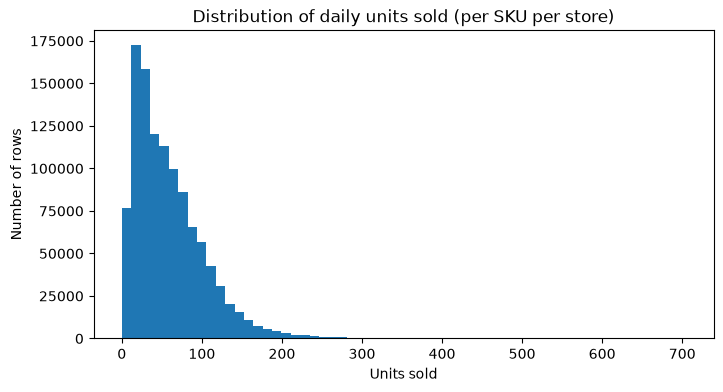

In [24]:
#Histogram of daily units sold: what does the distribution look like?
plt.figure(figsize=(8, 4))
plt.hist(sales["units_sold"], bins=60)
plt.title("Distribution of daily units sold (per SKU per store)")
plt.xlabel("Units sold")
plt.ylabel("Number of rows")
plt.show()

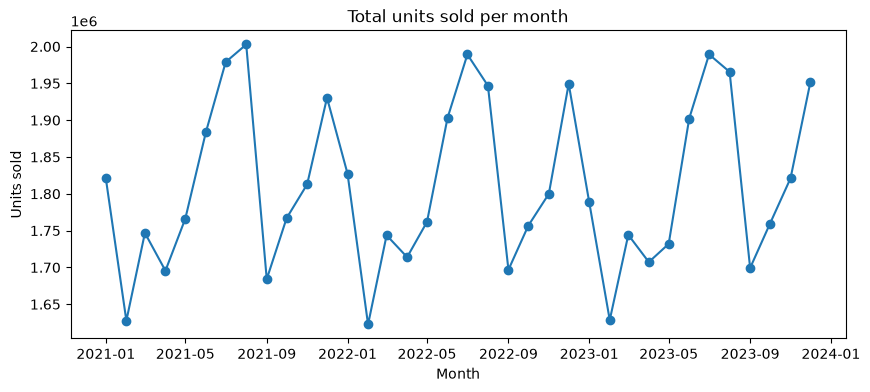

In [25]:
# Total units sold per month: is there a trend or seasonality?
monthly = sales.groupby(sales["date"].dt.to_period("M"))["units_sold"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Total units sold per month")
plt.xlabel("Month")
plt.ylabel("Units sold")
plt.show()

#### Coefficient of variation (CV) by region
**CV = standard deviation / mean.** It tells us how volatile demand is relative to its size, so it can compare small and big products fairly.

Products sell very different volumes, so I did not calculate one CV over all rows. Instead I calculated the CV of each product in each store over the 3 years, then took the average per country, channel and category.

In [26]:
# Mean and standard deviation of units sold for every store + SKU combination
series = sales.groupby(["country", "channel", "category", "store_id", "sku_id"])["units_sold"].agg(["mean", "std"]).reset_index()

# CV = std / mean
series["cv"] = series["std"] / series["mean"]
print("Number of store-SKU series:", len(series))
series["cv"].describe()

Number of store-SKU series: 1005


count    1005.000000
mean        0.415479
std         0.067295
min         0.322756
25%         0.351293
50%         0.399139
75%         0.478281
max         0.556199
Name: cv, dtype: float64

In [27]:
# Average CV by country, channel and category
cv_country  = series.groupby("country")["cv"].mean().sort_values(ascending=False)
cv_channel  = series.groupby("channel")["cv"].mean().sort_values(ascending=False)
cv_category = series.groupby("category")["cv"].mean().sort_values(ascending=False)

print(cv_country.round(3), "\n")
print(cv_channel.round(3), "\n")
print(cv_category.round(3))

country
Netherlands    0.424
Poland         0.418
France         0.417
Germany        0.416
Italy          0.415
Spain          0.414
Austria        0.412
Name: cv, dtype: float64 

channel
Convenience    0.424
E-commerce     0.415
Hypermarket    0.415
Supermarket    0.415
Name: cv, dtype: float64 

category
Beverages        0.455
Snacks           0.435
Personal Care    0.395
Home Care        0.386
Dairy            0.384
Name: cv, dtype: float64


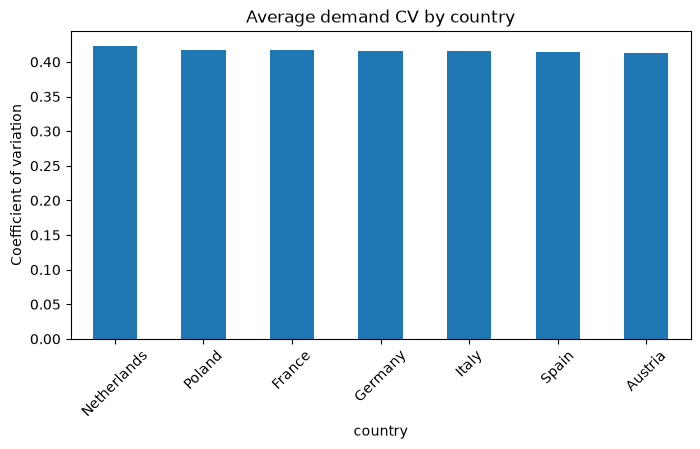

In [28]:
# Bar chart of CV by country (the axis starts at 0 so the size of the differences is honest)
plt.figure(figsize=(8, 4))
cv_country.plot(kind="bar")
plt.title("Average demand CV by country")
plt.ylabel("Coefficient of variation")
plt.xticks(rotation=45)
plt.show()

### 2. Geospatial and logistics analysis
First I made one summary row per store.

In [29]:
# One row per store with totals and averages
store_summary = sales.groupby(["store_id", "city", "country", "channel", "latitude", "longitude"]).agg(
    total_units=("units_sold", "sum"),
    total_net_sales=("net_sales", "sum"),
    avg_lead_time=("lead_time_days", "mean"),
    lead_time_std=("lead_time_days", "std"),
    stockout_rate=("stock_out_flag", "mean"),
).reset_index()

store_summary.sort_values("total_net_sales", ascending=False).round(3)

,store_id,city,country,channel,latitude,longitude,total_units,total_net_sales,avg_lead_time,lead_time_std,stockout_rate
3,STORE0004,Berlin,Germany,Hypermarket,52.501,13.421,6057129,46585753.18,6.505,2.014,0.030
7,STORE0008,Vienna,Austria,Hypermarket,48.203,16.359,5742174,43020025.97,6.494,2.008,0.031
5,STORE0006,Paris,France,Hypermarket,48.876,2.360,6014974,42601612.57,6.500,2.016,0.031
4,STORE0005,Warsaw,Poland,Hypermarket,52.253,20.996,5860180,42385262.52,6.506,2.016,0.030
10,STORE0011,Rome,Italy,Hypermarket,41.908,12.513,5985522,42205660.63,6.497,2.014,0.030
0,STORE0001,Berlin,Germany,Hypermarket,52.526,13.391,5681442,41939805.83,6.506,2.009,0.030
11,STORE0012,Madrid,Spain,E-commerce,40.417,-3.675,5243338,38965417.77,6.512,2.019,0.031
8,STORE0009,Barcelona,Spain,E-commerce,41.367,2.157,5297695,37766116.12,6.497,2.017,0.030
9,STORE0010,Milan,Italy,E-commerce,45.463,9.197,5106947,36002989.23,6.495,2.008,0.030
1,STORE0002,Rome,Italy,Supermarket,41.940,12.506,4249838,30231862.00,6.499,2.012,0.031


With only 13 stores, a smooth heat map would not be meaningful, so I used a bubble map: each bubble is a store, positioned by its latitude and longitude, and the bubble size is its total net sales.

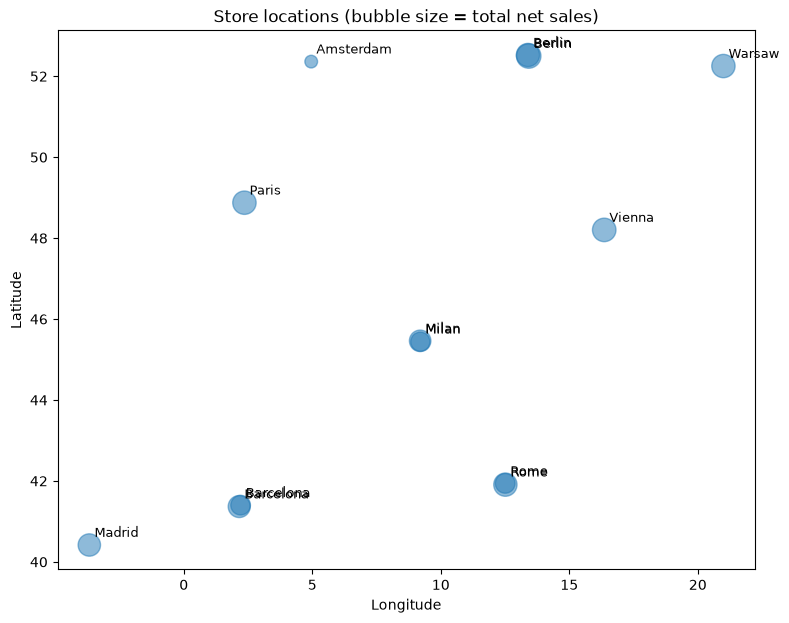

In [30]:
plt.figure(figsize=(9, 7))
plt.scatter(store_summary["longitude"], store_summary["latitude"],
            s=store_summary["total_net_sales"] / 150000, alpha=0.5)

# Write the city name next to each bubble
for i, row in store_summary.iterrows():
    plt.text(row["longitude"] + 0.2, row["latitude"] + 0.2, row["city"], fontsize=9)

plt.title("Store locations (bubble size = total net sales)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

#### Lead time and stockouts
**Logistics desert idea:** a store with high demand and unstable lead times is at risk. I plotted total units against lead-time variability (standard deviation) for each store.

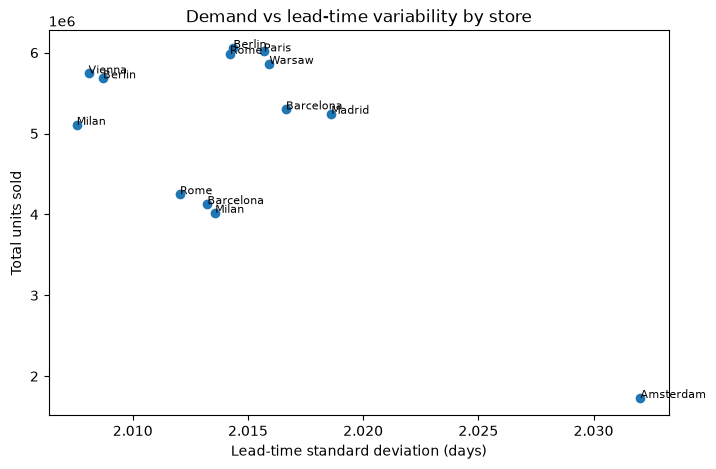

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(store_summary["lead_time_std"], store_summary["total_units"])
for i, row in store_summary.iterrows():
    plt.text(row["lead_time_std"], row["total_units"], row["city"], fontsize=8)

plt.title("Demand vs lead-time variability by store")
plt.xlabel("Lead-time standard deviation (days)")
plt.ylabel("Total units sold")
plt.show()

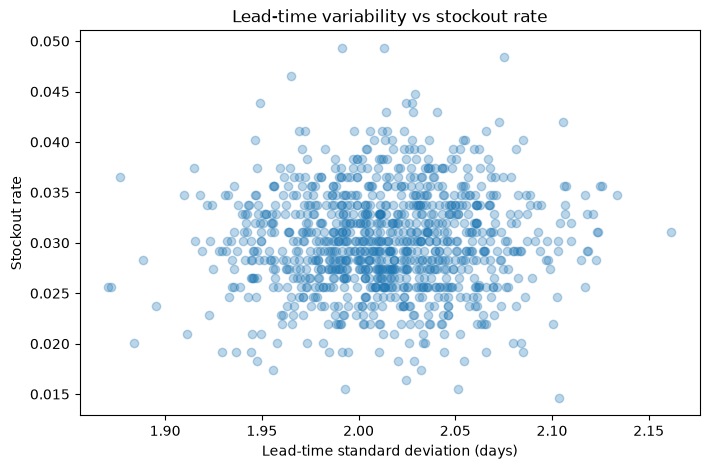

               lead_time_std  stockout_rate
lead_time_std          1.000          0.053
stockout_rate          0.053          1.000


In [32]:
# Scatter plot: lead-time variability vs stockout rate, one point per store + SKU
store_sku = sales.groupby(["store_id", "sku_id"]).agg(
    lead_time_std=("lead_time_days", "std"),
    stockout_rate=("stock_out_flag", "mean"),
).reset_index()

plt.figure(figsize=(8, 5))
plt.scatter(store_sku["lead_time_std"], store_sku["stockout_rate"], alpha=0.3)
plt.title("Lead-time variability vs stockout rate")
plt.xlabel("Lead-time standard deviation (days)")
plt.ylabel("Stockout rate")
plt.show()

# How strong is the relationship? (correlation is between -1 and 1; near 0 means no relationship)
print(store_sku[["lead_time_std", "stockout_rate"]].corr().round(3))

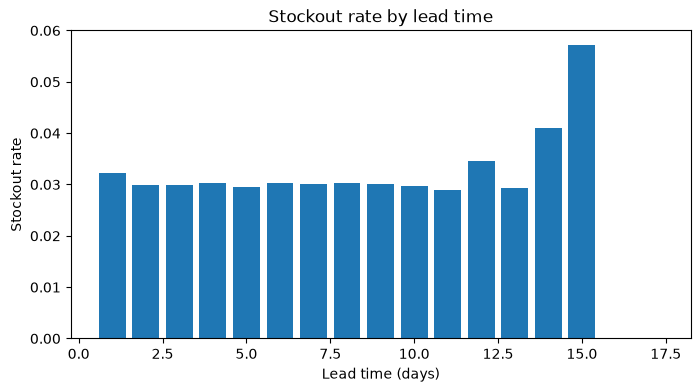

In [33]:
# A more direct look: the stockout rate for each lead time (in days) at the row level
stockout_by_lead = sales.groupby("lead_time_days")["stock_out_flag"].mean()

plt.figure(figsize=(8, 4))
plt.bar(stockout_by_lead.index, stockout_by_lead.values)
plt.title("Stockout rate by lead time")
plt.xlabel("Lead time (days)")
plt.ylabel("Stockout rate")
plt.show()

### 3. ABC analysis (by revenue)
I ranked the SKUs by total net sales and worked out each one's cumulative share of revenue:
- **A** = the SKUs that make up the first 80% of revenue
- **B** = the next 15%
- **C** = the last 5%

In [34]:
# Total net sales per SKU, highest first
sku_revenue = sales.groupby("sku_id")["net_sales"].sum().sort_values(ascending=False).reset_index()

# Share of total revenue and the running (cumulative) share
sku_revenue["revenue_share"] = sku_revenue["net_sales"] / sku_revenue["net_sales"].sum()
sku_revenue["cum_share"] = sku_revenue["revenue_share"].cumsum()

# Assign the class using the cumulative share (the 1.01 is just to catch rounding at 100%)
sku_revenue["abc_class"] = pd.cut(sku_revenue["cum_share"], bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

sku_revenue.head()

,sku_id,net_sales,revenue_share,cum_share,abc_class
0,SKU0018,17032424.64,0.036013,0.036013,A
1,SKU0027,16000295.02,0.033831,0.069845,A
2,SKU0026,13025419.73,0.027541,0.097386,A
3,SKU0099,12968809.43,0.027421,0.124807,A
4,SKU0092,12496995.90,0.026424,0.151231,A


In [35]:
# How many SKUs are in each class and how much revenue do they bring?
sku_revenue.groupby("abc_class", observed=True).agg(
    n_skus=("sku_id", "count"),
    revenue_share=("revenue_share", "sum"),
).round(3)

,n_skus,revenue_share
abc_class,,
A,49,0.794
B,29,0.156
C,24,0.050


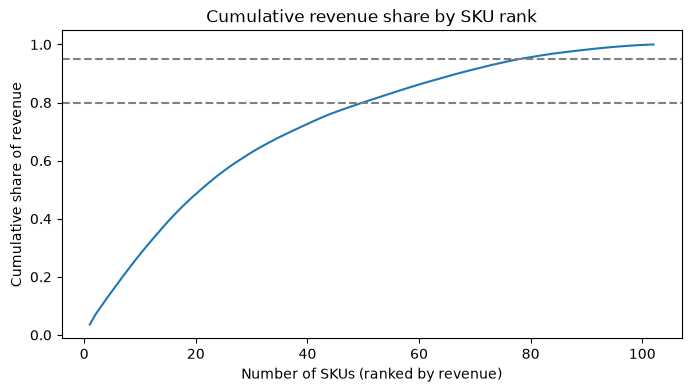

In [36]:
# Pareto-style chart: cumulative revenue share as we add SKUs
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(sku_revenue) + 1), sku_revenue["cum_share"])
plt.axhline(0.80, linestyle="--", color="gray")
plt.axhline(0.95, linestyle="--", color="gray")
plt.title("Cumulative revenue share by SKU rank")
plt.xlabel("Number of SKUs (ranked by revenue)")
plt.ylabel("Cumulative share of revenue")
plt.show()

### 4. XYZ analysis (by demand variability)
For each SKU I added up the units sold across all stores for every day, then calculated the CV of that daily total.

In [37]:
# Daily total units for each SKU (all stores together)
daily_sku = sales.groupby(["sku_id", "date"])["units_sold"].sum().reset_index()

# Mean, std and CV per SKU
sku_cv = daily_sku.groupby("sku_id")["units_sold"].agg(["mean", "std"])
sku_cv["cv"] = sku_cv["std"] / sku_cv["mean"]

print(sku_cv["cv"].describe().round(3))

count    102.000
mean       0.247
std        0.100
min        0.125
25%        0.144
50%        0.235
75%        0.340
max        0.419
Name: cv, dtype: float64


In [38]:
# Common textbook limits are X: CV up to 0.5, Y: 0.5 to 1.0, Z: above 1.0. How many SKUs are above 0.5?
print("SKUs with CV above 0.5:", (sku_cv["cv"] > 0.5).sum())

SKUs with CV above 0.5: 0


**Observation:** no SKU has a CV above 0.5, so the textbook limits would label every SKU as X and tell us nothing. Because demand is quite stable across the board in this dataset, I used a relative split instead: the third of SKUs with the lowest CV are X, the middle third Y and the highest third Z. 

In [39]:
# Split the SKUs into three equal-sized groups by CV
sku_cv["xyz_class"] = pd.qcut(sku_cv["cv"], 3, labels=["X", "Y", "Z"])

# What CV range does each class cover?
sku_cv.groupby("xyz_class", observed=True)["cv"].agg(["count", "min", "max"]).round(3)

,count,min,max
xyz_class,,,
X,34,0.125,0.151
Y,34,0.151,0.334
Z,34,0.335,0.419


### 5. Combined ABC-XYZ matrix

In [40]:
# Bring the SKU names and categories in, then combine the two classifications
sku_info = sales[["sku_id", "sku_name", "category"]].drop_duplicates()

segments = sku_revenue.merge(sku_cv[["cv", "xyz_class"]], on="sku_id").merge(sku_info, on="sku_id")
segments["segment"] = segments["abc_class"].astype(str) + segments["xyz_class"].astype(str)

# Matrix: number of SKUs in each ABC / XYZ combination
pd.crosstab(segments["abc_class"], segments["xyz_class"])

xyz_class,X,Y,Z
abc_class,,,
A,17,15,17
B,9,9,11
C,8,10,6


In [41]:
# Which categories do the A-class SKUs belong to?
pd.crosstab(segments["category"], segments["abc_class"])

abc_class,A,B,C
category,,,
Beverages,10,8,6
Dairy,8,4,6
Home Care,10,4,4
Personal Care,8,7,3
Snacks,13,6,5


### 6. Regional comparison
I repeated the ABC analysis inside each country to see if a SKU's class changes from country to country.

In [42]:
# Revenue of each SKU in each country
country_rev = sales.groupby(["country", "sku_id"])["net_sales"].sum().reset_index()

# Rank within each country and work out the cumulative share inside that country
country_rev = country_rev.sort_values(["country", "net_sales"], ascending=[True, False])
country_total = country_rev.groupby("country")["net_sales"].transform("sum")
country_rev["share"] = country_rev["net_sales"] / country_total
country_rev["cum_share"] = country_rev.groupby("country")["share"].cumsum()

country_rev["abc_class"] = pd.cut(country_rev["cum_share"], bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

# How many SKUs of each class does each country have?
pd.crosstab(country_rev["country"], country_rev["abc_class"])

abc_class,A,B,C
country,,,
Austria,38,23,19
France,37,23,20
Germany,44,28,26
Italy,49,29,24
Netherlands,21,13,11
Poland,39,23,18
Spain,46,29,25


In [43]:
# One row per SKU, one column per country, showing its class there
abc_by_country = country_rev.pivot(index="sku_id", columns="country", values="abc_class")

# SKUs that are an A-product in at least one country AND a C-product in another
is_A_somewhere = (abc_by_country == "A").any(axis=1)
is_C_somewhere = (abc_by_country == "C").any(axis=1)
switchers = abc_by_country[is_A_somewhere & is_C_somewhere]

print(len(switchers), "SKUs are A in one country and C in another")
switchers.head(10)

6 SKUs are A in one country and C in another


country,Austria,France,Germany,Italy,Netherlands,Poland,Spain
sku_id,,,,,,,
SKU0014,B,NaN,B,A,B,B,C
SKU0043,B,NaN,C,A,NaN,B,B
SKU0049,A,NaN,A,C,A,A,A
SKU0072,B,B,A,C,NaN,B,A
SKU0080,A,NaN,B,C,A,A,A
SKU0088,B,B,C,A,NaN,B,B


### 7. Save the SKU segments for the next steps

In [44]:
segments.to_csv("data/processed/sku_segments.csv", index=False)
print("Saved", len(segments), "SKUs")
segments.head()

Saved 102 SKUs


,sku_id,net_sales,revenue_share,cum_share,abc_class,cv,xyz_class,sku_name,category,segment
0,SKU0018,17032424.64,0.036013,0.036013,A,0.236804,Y,BrandF Water,Beverages,AY
1,SKU0027,16000295.02,0.033831,0.069845,A,0.333479,Y,BrandC Chips,Snacks,AY
2,SKU0026,13025419.73,0.027541,0.097386,A,0.175707,Y,BrandB Chips,Snacks,AY
3,SKU0099,12968809.43,0.027421,0.124807,A,0.341418,Z,BrandC Toothpaste,Personal Care,AZ
4,SKU0092,12496995.90,0.026424,0.151231,A,0.138370,X,BrandB Soap,Personal Care,AX


# Step 3: Statistical Rigor and Hypothesis Testing

What I want to find out:
1. How are price, promotion and sales volume related? (correlation matrix)
2. How sensitive is demand to price for the A-class products? (price elasticity)
3. Do promotions really increase sales, or is it just chance? (hypothesis test)
4. How should I split the data into training and test sets for a time series? (time-based split)

In [45]:
# Extra libraries needed for Step 3 (pandas and matplotlib were imported in Step 1)
import numpy as np
import seaborn as sns
from scipy import stats

# The price a customer actually pays = list price minus the discount
sales["net_price"] = sales["list_price"] * (1 - sales["promo_discount"])
print(sales.shape)
sales.info()

(1100000, 34)
<class 'pandas.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 34 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   date            1100000 non-null  datetime64[us]
 1   year            1100000 non-null  int64         
 2   month           1100000 non-null  int64         
 3   day             1100000 non-null  int64         
 4   weekofyear      1100000 non-null  int64         
 5   weekday         1100000 non-null  int64         
 6   is_weekend      1100000 non-null  int64         
 7   is_holiday      1100000 non-null  int64         
 8   temperature     1100000 non-null  float64       
 9   rain_mm         1100000 non-null  float64       
 10  store_id        1100000 non-null  str           
 11  country         1100000 non-null  str           
 12  city            1100000 non-null  str           
 13  channel         1100000 non-null  str           
 14  latitude       

### 1. How do price and promotions work in this data?
Before any statistics, we need to do two quick checks.

In [46]:
# 1) Does the list price of a SKU ever change?
print("Most different list prices for one SKU:", sales.groupby("sku_id")["list_price"].nunique().max())

# 2) How many SKUs are ever on promotion?
promo_days_per_sku = sales.groupby("sku_id")["on_promo"].sum()
print("SKUs with promo days:", (promo_days_per_sku > 0).sum())
print("SKUs never on promo :", (promo_days_per_sku == 0).sum())

# 3) Which discount levels exist?
print("Discount levels:", sorted(sales["promo_discount"].unique()))

Most different list prices for one SKU: 1
SKUs with promo days: 41
SKUs never on promo : 61
Discount levels: [np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3)]


**What this means:**
- The list price of every SKU is constant, so the only way a product's price changes over time is through a **promotional discount**.
- Many SKUs are **never promoted**, so they have no price changes at all. I cannot measure price elasticity for them.

### 2. Correlation matrix
Correlation measures how two variables move together, from -1 (opposite directions) through 0 (no relationship) to +1 (same direction).

I added one extra column, `units_vs_sku_avg`, which is units sold divided by that SKU's own average. It removes the fact that some products simply sell more than others, so it shows the effect of price and promotion (within) each product.

In [47]:
# Units relative to each SKU's own average (1.0 = a normal day for that SKU)
sales["units_vs_sku_avg"] = sales["units_sold"] / sales.groupby("sku_id")["units_sold"].transform("mean")

corr_cols = ["units_sold", "units_vs_sku_avg", "list_price", "promo_discount", "on_promo"]
corr = sales[corr_cols].corr()
corr.round(3)

,units_sold,units_vs_sku_avg,list_price,promo_discount,on_promo
units_sold,1.000,0.618,-0.083,0.293,0.296
units_vs_sku_avg,0.618,1.000,0.000,0.384,0.383
list_price,-0.083,0.000,1.000,-0.043,-0.048
promo_discount,0.293,0.384,-0.043,1.000,0.925
on_promo,0.296,0.383,-0.048,0.925,1.000


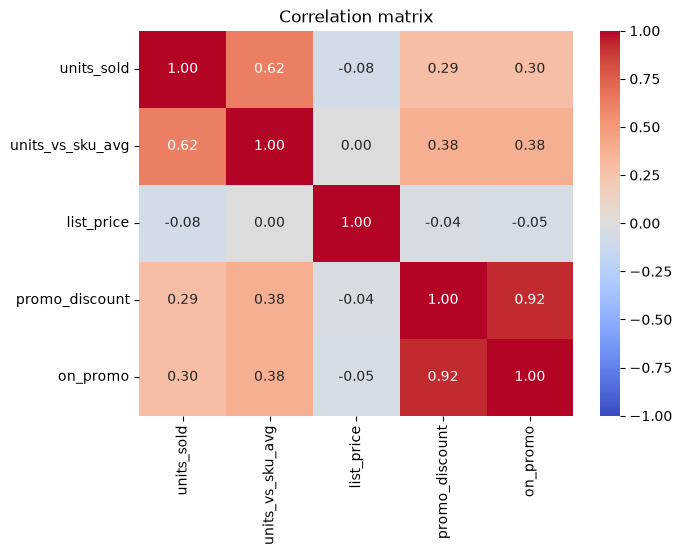

In [48]:
# Heat map of the correlations
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### 3. Price elasticity for the A-class products
**Price elasticity** = the % change in units sold when the price changes by 1%.

I use a **log-log regression**: I take the logarithm of units and of price and fit a straight line. The slope of that line is the elasticity. For example, a slope of -2 means a 1% lower price gives about 2% more units.

I did this separately for each A-class SKU, using the net price (list price after discount). I left out zero-sales days because the log of 0 does not exist.

In [49]:
# A-class SKUs from Step 2
a_skus = segments.loc[segments["abc_class"] == "A", "sku_id"].tolist()

# Elasticity needs a price that changes, so keep only the A-SKUs that are ever on promotion
a_skus_promoted = [sku for sku in a_skus if promo_days_per_sku[sku] > 0]

print("A-class SKUs                               :", len(a_skus))
print("A-class SKUs of which have price changes   :", len(a_skus_promoted))
print("A-class SKUsnever promoted (no elasticity) :", len(a_skus) - len(a_skus_promoted))

A-class SKUs                               : 49
A-class SKUs of which have price changes   : 20
A-class SKUsnever promoted (no elasticity) : 29


In [50]:
def get_elasticity(data):
    # Drop zero-sales days (log of 0 does not exist)
    data = data[data["units_sold"] > 0]
    # Fit: log(units) = intercept + slope * log(price). The slope is the elasticity.
    result = stats.linregress(np.log(data["net_price"]), np.log(data["units_sold"]))
    return result.slope, result.pvalue


# Calculate the elasticity of every A-SKU that has promotions, using all its days
results = []
for sku in a_skus_promoted:
    sku_data = sales[sales["sku_id"] == sku]
    slope, p_value = get_elasticity(sku_data)
    results.append({"sku_id": sku, "elasticity": slope, "p_value": p_value})

elasticity_all = pd.DataFrame(results)
print("Elasticity of A-SKUs (all days):")
print(elasticity_all["elasticity"].describe().round(2))
print("SKUs with a significant result (p < 0.05):", (elasticity_all["p_value"] < 0.05).sum(), "of", len(elasticity_all))

Elasticity of A-SKUs (all days):
count    20.00
mean     -2.53
std       0.06
min      -2.69
25%      -2.56
50%      -2.54
75%      -2.49
max      -2.42
Name: elasticity, dtype: float64
SKUs with a significant result (p < 0.05): 20 of 20


The result above mixes two things: whether a promotion is running at all, and how deep the discount is. To separate them, I repeated the calculation using **only promotion days**, so the price only changed between the 10%, 15%, 20% and 30% discount levels.

In [51]:
# Same calculation, but only on days when a promotion was running
results = []
for sku in a_skus_promoted:
    sku_data = sales[(sales["sku_id"] == sku) & (sales["on_promo"] == 1)]
    slope, p_value = get_elasticity(sku_data)
    results.append({"sku_id": sku, "elasticity": slope, "p_value": p_value})

elasticity_promo = pd.DataFrame(results)
print("Elasticity of A-SKUs (promotion days only):")
print(elasticity_promo["elasticity"].describe().round(2))

Elasticity of A-SKUs (promotion days only):
count    20.00
mean     -0.86
std       0.14
min      -1.07
25%      -0.96
50%      -0.90
75%      -0.74
max      -0.54
Name: elasticity, dtype: float64


In [52]:
# Compare the two results side by side
comparison = pd.DataFrame({
    "all_days": elasticity_all["elasticity"].describe(),
    "promo_days_only": elasticity_promo["elasticity"].describe(),
}).round(2)
comparison

,all_days,promo_days_only
count,20.00,20.00
mean,-2.53,-0.86
std,0.06,0.14
min,-2.69,-1.07
25%,-2.56,-0.96
50%,-2.54,-0.90
75%,-2.49,-0.74
max,-2.42,-0.54


**How to read this:** an elasticity below -1 means demand is *elastic* (a price cut brings a more-than-proportional rise in units, so revenue goes up). Between -1 and 0 it is *inelastic*. The two numbers answer different questions. The first says how much demand rises when a product goes on promotion. The second says how much *extra* demand a deeper discount adds once a promotion is already running.

### 4. Hypothesis test: do promotions increase sales?
* **H0 (null hypothesis):** average units sold on promotion days = average units sold on non-promotion days.
* **H1 (alternative):** the averages are different.
* **Significance level:** alpha = 0.05. If the p-value is below 0.05, I reject H0.

I run two tests:
* **Welch's t-test** compares the two averages (it does not assume equal variances).
* **Mann-Whitney U test** compares the two distributions without assuming a normal shape. Daily sales are right-skewed (Step 2), so this one is a good fit.

In [53]:
# Average sales on promotion days vs non-promotion days
group_stats = sales.groupby("on_promo")["units_sold"].agg(["mean", "median", "std", "count"]).round(1)
group_stats.index = ["No promotion", "Promotion"]
group_stats

,mean,median,std,count
No promotion,55.3,46.0,39.2,1011743
Promotion,104.3,89.0,73.7,88257


In [54]:
promo_units = sales.loc[sales["on_promo"] == 1, "units_sold"]
no_promo_units = sales.loc[sales["on_promo"] == 0, "units_sold"]

# Lift = how much higher is the promotion average, in %
lift = (promo_units.mean() / no_promo_units.mean() - 1) * 100
print(f"Promotion lift: {lift:.1f}%")

# Run both tests
t_stat, t_p = stats.ttest_ind(promo_units, no_promo_units, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(promo_units, no_promo_units)

alpha = 0.05
# A p-value shown as 0.0 means it is too small for the computer to display: report it as p < 0.001
print("T-test p-value       :", t_p)
print("Mann-Whitney p-value :", u_p)

if t_p < alpha and u_p < alpha:
    print("Both p-values are below 0.05, so I reject H0: promotions change sales.")
else:
    print("I cannot reject H0.")

Promotion lift: 88.7%
T-test p-value       : 0.0
Mann-Whitney p-value : 0.0
Both p-values are below 0.05, so I reject H0: promotions change sales.


#### Robustness check
A fair worry: maybe the promoted products are simply bigger sellers. To check, I compare promotion days and non-promotion days **inside the same product and store**. Only SKUs that are ever promoted are included. If promotions really work, almost every store-SKU should sell more on its promo days.

In [55]:
# Keep only SKUs that are ever promoted
promoted_skus = promo_days_per_sku[promo_days_per_sku > 0].index
promoted = sales[sales["sku_id"].isin(promoted_skus)]

# Average units on promo days and non-promo days for each store + SKU
series_avg = promoted.groupby(["store_id", "sku_id", "on_promo"])["units_sold"].mean().unstack()
series_avg = series_avg.dropna()                      # keep series that have both kinds of days
series_avg.columns = ["non_promo_avg", "promo_avg"]   # the columns are in the order 0, 1
series_avg["lift"] = series_avg["promo_avg"] / series_avg["non_promo_avg"]

print("Store-SKU series compared:", len(series_avg))
print("Series that sell more on promo days:", (series_avg["lift"] > 1).sum())
print("Average lift (promo avg / normal avg):", round(series_avg["lift"].mean(), 2))
print("Lowest / highest lift:", round(series_avg["lift"].min(), 2), "/", round(series_avg["lift"].max(), 2))

# Paired t-test: the same series measured twice (on promo days and on normal days)
paired_t, paired_p = stats.ttest_rel(series_avg["promo_avg"], series_avg["non_promo_avg"])
print("Paired t-test p-value:", paired_p)

Store-SKU series compared: 403
Series that sell more on promo days: 403
Average lift (promo avg / normal avg): 1.87
Lowest / highest lift: 1.7 / 2.03
Paired t-test p-value: 6.82215376492626e-129


promo_discount
0.00     55.3
0.10     94.3
0.15    100.3
0.20    106.7
0.30    116.2
Name: units_sold, dtype: float64


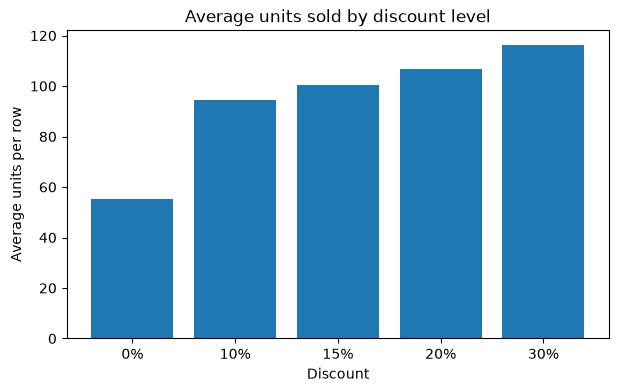

In [56]:
# Does a deeper discount sell more? Average units by discount level
by_discount = sales.groupby("promo_discount")["units_sold"].mean().round(1)
print(by_discount)

plt.figure(figsize=(7, 4))
plt.bar(["0%", "10%", "15%", "20%", "30%"], by_discount.values)
plt.title("Average units sold by discount level")
plt.xlabel("Discount")
plt.ylabel("Average units per row")
plt.show()

**Important to note:** these tests assume the observations are independent, but daily sales of one product in one store are linked over time. That makes the p-values look (better than they really are). With more than a million rows the p-value will be tiny almost no matter what, so the **size of the lift** (about +89%) is more informative than the p-value itself.

### 5. Time-series split (train and test)
**Warning from the guide:** never shuffle a time series randomly. Random shuffling would put future days in the training set and past days in the test set, which would leak information and make the model look better than it really is.

Instead I used a **time-based split**: the last 6 months (July to December 2023) are the hold-out test set, and everything before is the training set.

In [57]:
SPLIT_DATE = pd.Timestamp("2023-07-01")

train = sales[sales["date"] < SPLIT_DATE]
test = sales[sales["date"] >= SPLIT_DATE]

print("Train:", len(train), "rows |", train["date"].min().date(), "to", train["date"].max().date())
print("Test :", len(test), "rows |", test["date"].min().date(), "to", test["date"].max().date())
print(f"Test share of all rows: {len(test) / len(sales):.1%}")

# The most important check: every training date comes before every test date
print("Training ends before test starts:", train["date"].max() < test["date"].min())

Train: 915264 rows | 2021-01-01 to 2023-06-30
Test : 184736 rows | 2023-07-01 to 2023-12-31
Test share of all rows: 16.8%
Training ends before test starts: True


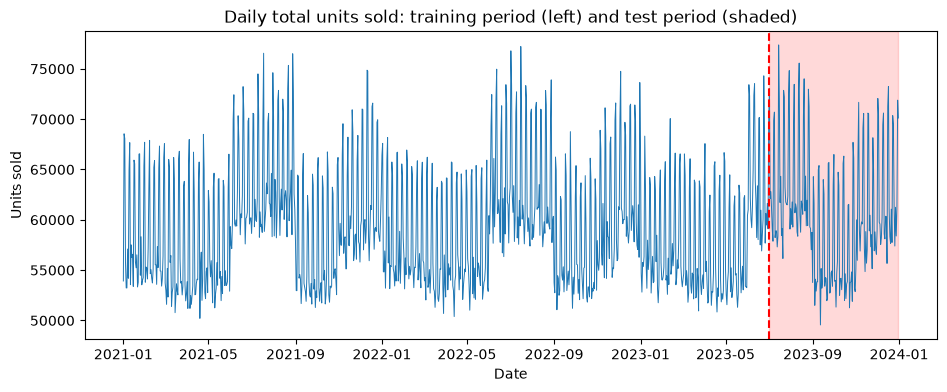

In [58]:
# Plot total daily units and mark the split
daily_total = sales.groupby("date")["units_sold"].sum()

plt.figure(figsize=(11, 4))
plt.plot(daily_total.index, daily_total.values, linewidth=0.7)
plt.axvline(SPLIT_DATE, color="red", linestyle="--")
plt.axvspan(SPLIT_DATE, daily_total.index.max(), alpha=0.15, color="red")
plt.title("Daily total units sold: training period (left) and test period (shaded)")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.show()

In [59]:
# Are the train and test sets similar? (promotion share and average sales)
check = pd.DataFrame({
    "promo_share": [train["on_promo"].mean(), test["on_promo"].mean()],
    "avg_units": [train["units_sold"].mean(), test["units_sold"].mean()],
}, index=["Train", "Test"]).round(3)
check

,promo_share,avg_units
Train,0.08,58.923
Test,0.08,60.552


The test period contains the summer peak (July and August) and the December peak. The training data includes those same seasons for 2021 and 2022.

# Step 4: Feature Engineering and Preprocessing¶
What I want to do:

1. Pick the 10 SKUs I will forecast (a mix of ABC-XYZ profiles)
2. Create features that capture the momentum of demand: lags and a 7-day rolling mean
3. Add calendar features (weekend, holiday, month start/end)
4. Turn categories (channel, country, city) into numbers
5. Split by date and scale the numeric features, fitting the scaler on the training data only
   
**The rule for every feature:** it must be something I would know before the day I am forecasting. Lags use sales from earlier days. Promotions are planned in advance, so they are known. The calendar is known. This way the model forecasts one day ahead without cheating.

In [60]:
# Extra libraries for Step 4 (pandas, numpy and matplotlib were imported earlier)
import joblib #Package for efficient serialization of Python objects, especially those containing large data like NumPy arrays
from sklearn.preprocessing import StandardScaler, LabelEncoder

### 1. Choose the 10 SKUs to forecast
The guide asks for 10 SKUs with different demand profiles, for example 2 from AX, 2 from BY and 2 from CZ. In each ABC-XYZ segment, I took the SKUs with the highest revenue.

In [61]:
# How many SKUs to take from each ABC-XYZ segment (10 in total)
picks = {"AX": 2, "AZ": 1, "BY": 2, "BZ": 1, "CX": 1, "CY": 1, "CZ": 2}

# Rank all SKUs by revenue, highest first, so that head(n) gives the top n of a segment
ranked = segments.sort_values("net_sales", ascending=False)

selected = []
for segment_name, n in picks.items():
    top_skus = ranked.loc[ranked["segment"] == segment_name, "sku_id"].head(n).tolist()
    selected = selected + top_skus

print(len(selected), "SKUs selected:", selected)

10 SKUs selected: ['SKU0092', 'SKU0100', 'SKU0099', 'SKU0035', 'SKU0024', 'SKU0080', 'SKU0084', 'SKU0056', 'SKU0040', 'SKU0019']


In [62]:
# Look at the selected SKUs, with the number of promotion days each one had
selected_info = ranked[ranked["sku_id"].isin(selected)][["sku_id", "sku_name", "category", "segment", "cv"]].copy()
selected_info["promo_days"] = selected_info["sku_id"].map(sales.groupby("sku_id")["on_promo"].sum()).astype(int)
selected_info.sort_values("segment").round(3)

,sku_id,sku_name,category,segment,cv,promo_days
4,SKU0092,BrandB Soap,Personal Care,AX,0.138,0
5,SKU0100,BrandD Toothpaste,Personal Care,AX,0.135,0
3,SKU0099,BrandC Toothpaste,Personal Care,AZ,0.341,2409
51,SKU0035,BrandE Chocolate,Snacks,BY,0.268,0
60,SKU0024,BrandF Energy drink,Beverages,BY,0.249,0
49,SKU0080,BrandB Cleaner,Home Care,BZ,0.340,1752
80,SKU0084,BrandF Cleaner,Home Care,CX,0.132,0
78,SKU0056,BrandB Milk,Dairy,CY,0.334,2628
82,SKU0040,BrandD Biscuits,Snacks,CZ,0.337,2409
85,SKU0019,BrandA Energy drink,Beverages,CZ,0.390,2190


**Observation:** the X SKUs (stable demand) have no promotion days, and the Z SKUs (erratic demand) are promoted. So the "erratic" SKUs are erratic mostly because of promotions.

### 2. Subset the data and sort it
I keep only the 10 SKUs and only the columns I needed. Lags only make sense if the rows are in date order **inside each store-SKU series**, so I sorted by store, SKU and date.

In [63]:
keep_cols = ["date", "store_id", "sku_id", "country", "city", "channel", "lead_time_days",
             "stock_on_hand", "stock_out_flag", "units_sold", "list_price",
             "on_promo", "promo_discount", "is_weekend", "is_holiday"]

model_df = sales.loc[sales["sku_id"].isin(selected), keep_cols].copy()
model_df = model_df.sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)

print("Rows:", len(model_df))
print("Store-SKU series:", model_df.groupby(["store_id", "sku_id"]).ngroups)

Rows: 110595
Store-SKU series: 101


### 3. Lagged variables
A **lag** is the value from an earlier day. `lag_1` is yesterday's sales, `lag_7` is the same weekday last week and `lag_30` is about a month ago. They capture daily, weekly and monthly momentum.

`shift(n)` moves a column down by n rows. I do it with `groupby(["store_id", "sku_id"])` so that a series never borrows values from a different store or product.

In [64]:
# One group per store-SKU series
series_group = model_df.groupby(["store_id", "sku_id"])["units_sold"]

model_df["lag_1"] = series_group.shift(1)     # yesterday
model_df["lag_7"] = series_group.shift(7)     # same weekday last week
model_df["lag_30"] = series_group.shift(30)   # about one month ago

# Extra lagged values for the stockout model later: yesterday's stockout flag and stock level
model_df["lag_stockout_1"] = model_df.groupby(["store_id", "sku_id"])["stock_out_flag"].shift(1)
model_df["soh_lag_1"] = model_df.groupby(["store_id", "sku_id"])["stock_on_hand"].shift(1)

In [65]:
#Proof that shift(30) is calendar aligned
check = model_df.copy()
check["date_30_back"] = check.groupby(["store_id", "sku_id"])["date"].shift(30)
gap_days = (check["date"] - check["date_30_back"]).dt.days.dropna()
print("Gap between a row and its lag_30 source (days):", gap_days.unique())

Gap between a row and its lag_30 source (days): [30.]


### 4. Rolling mean (7 days)
The 7-day rolling mean is the average of the last 7 days. It smooths out the daily noise.

I use `shift(1)` **before** `rolling(7)` so that today's sales are not included. Otherwise the feature would contain the answer I am trying to predict.

In [66]:
# Average of the 7 days BEFORE today, calculated separately for each store-SKU series
model_df["rolling_mean_7"] = series_group.transform(lambda x: x.shift(1).rolling(7).mean())

In [67]:
# Check one series by eye: lag_1 must equal the previous row's units_sold
example = model_df[(model_df["store_id"] == model_df["store_id"].iloc[0]) & (model_df["sku_id"] == model_df["sku_id"].iloc[0])]
example[["date", "units_sold", "lag_1", "lag_7", "lag_30", "rolling_mean_7"]].iloc[28:38]

,date,units_sold,lag_1,lag_7,lag_30,rolling_mean_7
28,2021-01-29,15,11.0,7.0,NaN,15.285714
29,2021-01-30,9,15.0,20.0,NaN,16.428571
30,2021-01-31,21,9.0,13.0,21.0,14.857143
31,2021-02-01,22,21.0,18.0,28.0,16.000000
32,2021-02-02,55,22.0,17.0,14.0,16.571429
33,2021-02-03,24,55.0,21.0,18.0,22.000000
34,2021-02-04,24,24.0,11.0,20.0,22.428571
35,2021-02-05,17,24.0,15.0,17.0,24.285714
36,2021-02-06,21,17.0,9.0,20.0,24.571429
37,2021-02-07,22,21.0,21.0,15.0,26.285714


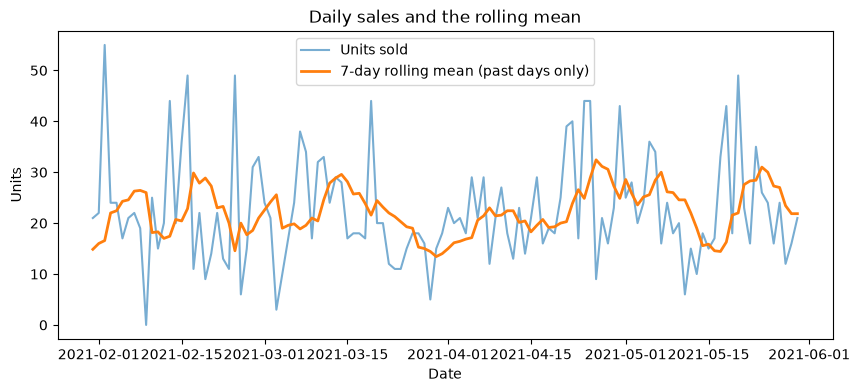

In [68]:
# Chart: daily sales and the 7-day rolling mean for the first 120 days of that series
first_120 = example.iloc[30:150]

plt.figure(figsize=(10, 4))
plt.plot(first_120["date"], first_120["units_sold"], label="Units sold", alpha=0.6)
plt.plot(first_120["date"], first_120["rolling_mean_7"], label="7-day rolling mean (past days only)", linewidth=2)
plt.title("Daily sales and the rolling mean")
plt.xlabel("Date")
plt.ylabel("Units")
plt.legend()
plt.show()

### 5. Calendar features
The data already has `is_weekend` and `is_holiday`. I added the day of the week, the month, and flags for the first and last day of the month.

In [69]:
model_df["day_of_week"] = model_df["date"].dt.dayofweek                       # Monday = 0 ... Sunday = 6
model_df["month"] = model_df["date"].dt.month                                 # 1 to 12 (captures seasonality)
model_df["is_month_start"] = model_df["date"].dt.is_month_start.astype(int)   # True/False -> 1/0
model_df["is_month_end"] = model_df["date"].dt.is_month_end.astype(int)

### 6. Remove rows without a full history
The first 30 days of every series have no `lag_30` (there is no data from before the start), so those rows have missing values. I dropped them.

In [70]:
rows_before = len(model_df)
model_df = model_df.dropna(subset=["lag_1", "lag_7", "lag_30", "rolling_mean_7"]).reset_index(drop=True)
print("Rows dropped:", rows_before - len(model_df), "| Rows left:", len(model_df))
print("Missing values left:", int(model_df.isnull().sum().sum()))

Rows dropped: 3030 | Rows left: 107565
Missing values left: 0


### 7. Encode the categories
Models need numbers, not text.
* **Channel** has 4 values, so I used **one-hot encoding**: one 0/1 column per channel. I dropped the first one (`drop_first=True`), because it can be worked out from the others.
* **Country and city** are replaced by a number with **label encoding**, as the guide says. The numbers are only codes and have no real order, which I needed to remember when reading the results.

In [71]:
# One-hot encoding of the channel
channel_dummies = pd.get_dummies(model_df["channel"], prefix="channel", drop_first=True, dtype=int)
model_df = pd.concat([model_df, channel_dummies], axis=1)

# Label encoding of country and city
model_df["country_code"] = LabelEncoder().fit_transform(model_df["country"])
model_df["city_code"] = LabelEncoder().fit_transform(model_df["city"])

print(channel_dummies.columns.tolist())
model_df[["country", "country_code", "city", "city_code"]].drop_duplicates().sort_values("country_code")

['channel_E-commerce', 'channel_Hypermarket', 'channel_Supermarket']


,country,country_code,city,city_code
60705,Austria,0,Vienna,7
43665,France,1,Paris,5
0,Germany,2,Berlin,2
10650,Italy,3,Rome,6
18105,Italy,3,Milan,4
101175,Netherlands,4,Amsterdam,0
36210,Poland,5,Warsaw,8
52185,Spain,6,Barcelona,1
92655,Spain,6,Madrid,3


### 8. Time-based split and scaling
Same split date as in Step 3: the last 6 months are the test set.

**Scaling** puts numeric features on a similar scale (mean 0, standard deviation 1). The important rule: **fit the scaler on the training set only**, then use it to transform both sets. If I fitted it on all the data, information from the test set would leak into the training.

I scaled only the continuous features. The 0/1 flags and the codes stay as they are, and the target `units_sold` stays in real units so that errors are in units.

In [72]:
SPLIT_DATE = pd.Timestamp("2023-07-01")   # same split as in Step 3

# Keep an unscaled copy of lag_7: it is the "same day last week" benchmark forecast used in Step 5
model_df["lag_7_raw"] = model_df["lag_7"]

train_df = model_df[model_df["date"] < SPLIT_DATE].copy()
test_df = model_df[model_df["date"] >= SPLIT_DATE].copy()
print("Train:", len(train_df), "rows | Test:", len(test_df), "rows")
print("Training ends before test starts:", train_df["date"].max() < test_df["date"].min())

Train: 88981 rows | Test: 18584 rows
Training ends before test starts: True


In [73]:
scale_cols = ["lag_1", "lag_7", "lag_30", "rolling_mean_7", "list_price"]

scaler = StandardScaler()
scaler.fit(train_df[scale_cols])          # learn the mean and std from the TRAINING data only

train_scaled = train_df.copy()
test_scaled = test_df.copy()
train_scaled[scale_cols] = scaler.transform(train_df[scale_cols])
test_scaled[scale_cols] = scaler.transform(test_df[scale_cols])

# Check: the training columns have mean 0 and std 1. The test columns do not, and that is correct.
print("Training set:")
print(train_scaled[scale_cols].agg(["mean", "std"]).round(3))
print()
print("Test set (scaled with the training numbers):")
print(test_scaled[scale_cols].agg(["mean", "std"]).round(3))

Training set:
      lag_1  lag_7  lag_30  rolling_mean_7  list_price
mean    0.0    0.0    -0.0            -0.0         0.0
std     1.0    1.0     1.0             1.0         1.0

Test set (scaled with the training numbers):
      lag_1  lag_7  lag_30  rolling_mean_7  list_price
mean  0.014  0.011  -0.012           0.012         0.0
std   1.030  1.016   0.956           1.026         1.0


### 9. Save the prepared data for Step 5

In [74]:
# Ensure the target directory exists
os.makedirs("data/processed", exist_ok=True)

train_scaled.to_csv("data/processed/model_train.csv.gz", index=False, compression="gzip")
test_scaled.to_csv("data/processed/model_test.csv.gz", index=False, compression="gzip")
joblib.dump(scaler, "data/processed/scaler.joblib")     # so the scaling can be reused exactly
print("Saved:", train_scaled.shape, test_scaled.shape)

Saved: (88981, 31) (18584, 31)


# Step 5: Machine Learning Forecasting

What I want to do:
1. Test whether the demand series are stationary (Augmented Dickey-Fuller test)
2. Build a benchmark and a baseline: a naive forecast and Linear Regression
3. Build two advanced models: Random Forest and Gradient Boosting
4. Compare them with MAE, RMSE and MAPE, overall and for each of the 10 SKUs
5. Predict stockouts and measure precision, recall and F1-Score

In [75]:
# Extra libraries for Step 5
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

### 1. Stationarity: Augmented Dickey-Fuller (ADF) test
A series is **stationary** if its average and spread do not drift over time. The ADF test checks this:
* **H0:** the series is *not* stationary (it has a unit root).
* **H1:** the series is stationary.
* If the **p-value is below 0.05**, I reject H0 and treat the series as stationary. If not, the guide says to apply **differencing** (subtract yesterday's value) and test again.

I tested the daily total units of each of the 10 SKUs (all stores added up), using the training period only.

In [76]:
# The 10 SKUs and their labels (name and ABC-XYZ segment)
selected = sorted(train_scaled["sku_id"].unique())
sku_labels = segments.set_index("sku_id").loc[selected, ["sku_name", "segment"]]

# Daily total units of each SKU in the training period
train_daily = train_scaled.groupby(["sku_id", "date"])["units_sold"].sum().reset_index()

adf_rows = []
for sku in selected:
    daily_series = train_daily.loc[train_daily["sku_id"] == sku, "units_sold"]
    adf_stat, p_value = adfuller(daily_series)[0:2]      # the function returns several values: I need the first two
    row = {"sku_id": sku, "segment": sku_labels.loc[sku, "segment"], "adf_stat": adf_stat, "p_value": p_value,
           "stationary": p_value < 0.05, "p_after_diff": np.nan}

    # If the series is not stationary, take the first difference and test again
    if p_value >= 0.05:
        differenced = daily_series.diff().dropna()
        row["p_after_diff"] = adfuller(differenced)[1]
    adf_rows.append(row)

adf_table = pd.DataFrame(adf_rows)
adf_table.round(4)

,sku_id,segment,adf_stat,p_value,stationary,p_after_diff
0,SKU0019,CZ,-3.8576,0.0024,True,NaN
1,SKU0024,BY,-2.3416,0.1589,False,0.0
2,SKU0035,BY,-2.7551,0.0650,False,0.0
3,SKU0040,CZ,-4.7018,0.0001,True,NaN
4,SKU0056,CY,-29.3170,0.0000,True,NaN
5,SKU0080,BZ,-7.3665,0.0000,True,NaN
6,SKU0084,CX,-5.6574,0.0000,True,NaN
7,SKU0092,AX,-6.2320,0.0000,True,NaN
8,SKU0099,AZ,-27.8817,0.0000,True,NaN
9,SKU0100,AX,-5.3342,0.0000,True,NaN


**Decision rule:** a series that passes the test (p < 0.05) can be used as it is. A series that fails is differenced, and the last column shows whether differencing fixes it.

The tree models (Random Forest and Gradient Boosting) do not need stationary data, and my features already describe the recent level of demand (the lags and the rolling mean). So I keep forecasting the **original units**, which is what planners need, and I note which series failed the test. Seasonality alone does not make a series fail this test.

### 2. Choose the model inputs and the evaluation measures

In [77]:
channel_cols = [c for c in train_scaled.columns if c.startswith("channel_")]

feature_cols = (["lag_1", "lag_7", "lag_30", "rolling_mean_7"]                      # momentum
                + ["on_promo", "promo_discount"]                                    # promotions
                + ["is_weekend", "is_holiday", "is_month_start", "is_month_end", "day_of_week", "month"]   # calendar
                + ["list_price"]                                                    # product
                + ["country_code", "city_code"] + channel_cols)                     # location and channel

X_train = train_scaled[feature_cols]
X_test = test_scaled[feature_cols]
y_train = train_scaled["units_sold"].values
y_test = test_scaled["units_sold"].values

print(len(feature_cols), "features:", feature_cols)

18 features: ['lag_1', 'lag_7', 'lag_30', 'rolling_mean_7', 'on_promo', 'promo_discount', 'is_weekend', 'is_holiday', 'is_month_start', 'is_month_end', 'day_of_week', 'month', 'list_price', 'country_code', 'city_code', 'channel_E-commerce', 'channel_Hypermarket', 'channel_Supermarket']


**Evaluation measures** (all calculated on the test set, in units):
* **MAE** (mean absolute error): the average size of the miss, in units.
* **RMSE** (root mean squared error): like MAE but big misses count more.
* **MAPE** (mean absolute percentage error): the average miss as a % of actual sales, easy to explain to managers and business stakeholders. It cannot be calculated on days with zero sales (division by zero), so those days are left out of the MAPE.

In [78]:
def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    nonzero = y_true > 0                                  # skip zero-sale days for MAPE
    mape = np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE_%": mape}

### 3. Models
* **Naive benchmark:** forecast = sales on the same weekday last week. Any useful model must beat this.
* **Linear Regression (baseline):** a straight-line relationship. It sets the performance floor.
* **Random Forest:** many decision trees, each trained on a random part of the data, averaged together. It can capture non-linear effects and interactions, such as promotion x season.
* **Gradient Boosting:** trees built one after another, each one correcting the mistakes of the previous ones.

Demand cannot be negative, so I set negative predictions to 0.

In [79]:
predictions = {}

# 1) Naive benchmark: same weekday last week (unscaled copy of lag_7)
predictions["Naive (same day last week)"] = test_scaled["lag_7_raw"].values

# 2) Linear Regression
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
predictions["Linear Regression"] = np.clip(lr_reg.predict(X_test), 0, None)

In [80]:
# 3) Random Forest
rf_reg = RandomForestRegressor(
    n_estimators=100,        # number of trees
    max_depth=12,            # limit how deep each tree can grow (prevents memorising the training data)
    min_samples_leaf=20,     # every leaf must have at least 20 rows
    random_state=42,         # makes the result repeatable
    n_jobs=-1,               # use all processor cores
)
rf_reg.fit(X_train, y_train)
predictions["Random Forest"] = np.clip(rf_reg.predict(X_test), 0, None)

In [81]:
# 4) Gradient Boosting
gb_reg = HistGradientBoostingRegressor(
    max_iter=200,            # number of boosting rounds (trees)
    learning_rate=0.1,       # how much each tree is allowed to correct
    max_depth=6,
    random_state=42,
)
gb_reg.fit(X_train, y_train)
predictions["Gradient Boosting"] = np.clip(gb_reg.predict(X_test), 0, None)

### 4. Compare the models

In [82]:
model_results = pd.DataFrame({name: get_metrics(y_test, pred) for name, pred in predictions.items()}).T.round(2)
model_results

,MAE,RMSE,MAPE_%
Naive (same day last week),26.65,41.65,69.21
Linear Regression,19.39,29.71,58.70
Random Forest,16.87,26.49,52.50
Gradient Boosting,16.82,26.39,52.57


Best model by MAE: Gradient Boosting


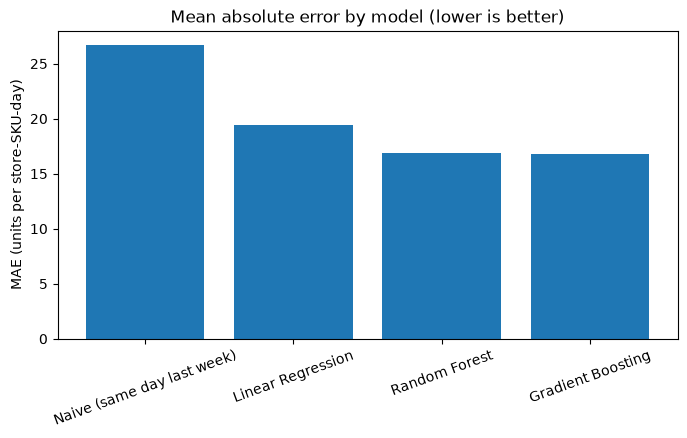

In [83]:
# Best of the machine learning models (lowest MAE)
ml_models = ["Linear Regression", "Random Forest", "Gradient Boosting"]
best_model = model_results.loc[ml_models, "MAE"].idxmin()
print("Best model by MAE:", best_model)

# Bar chart of MAE
plt.figure(figsize=(8, 4))
plt.bar(model_results.index, model_results["MAE"])
plt.title("Mean absolute error by model (lower is better)")
plt.ylabel("MAE (units per store-SKU-day)")
plt.xticks(rotation=20)
plt.show()

In [84]:
# Put the actual sales and every model's forecast in one table
test_results = test_scaled[["date", "store_id", "sku_id", "country", "city", "channel", "lead_time_days", "units_sold"]].copy()
for name, pred in predictions.items():
    test_results[name] = pred

# Performance of the best model for each of the 10 SKUs
sku_rows = []
for sku in selected:
    part = test_results[test_results["sku_id"] == sku]
    row = get_metrics(part["units_sold"].values, part[best_model].values)
    row["sku_id"] = sku
    row["name"] = sku_labels.loc[sku, "sku_name"]
    row["segment"] = sku_labels.loc[sku, "segment"]
    row["avg_units"] = part["units_sold"].mean()
    sku_rows.append(row)

per_sku = pd.DataFrame(sku_rows)[["sku_id", "name", "segment", "avg_units", "MAE", "RMSE", "MAPE_%"]].sort_values("segment")
per_sku.round(2)

,sku_id,name,segment,avg_units,MAE,RMSE,MAPE_%
7,SKU0092,BrandB Soap,AX,90.22,23.49,30.89,51.51
9,SKU0100,BrandD Toothpaste,AX,83.70,22.51,29.15,55.47
8,SKU0099,BrandC Toothpaste,AZ,106.13,27.77,37.97,57.38
1,SKU0024,BrandF Energy drink,BY,60.05,16.89,22.35,61.86
2,SKU0035,BrandE Chocolate,BY,124.25,34.25,45.95,57.84
5,SKU0080,BrandB Cleaner,BZ,84.41,22.01,30.08,53.19
6,SKU0084,BrandF Cleaner,CX,23.06,6.25,8.13,46.19
4,SKU0056,BrandB Milk,CY,24.21,6.49,8.77,46.66
0,SKU0019,BrandA Energy drink,CZ,21.75,6.05,8.18,54.49
3,SKU0040,BrandD Biscuits,CZ,21.46,5.62,7.65,44.51


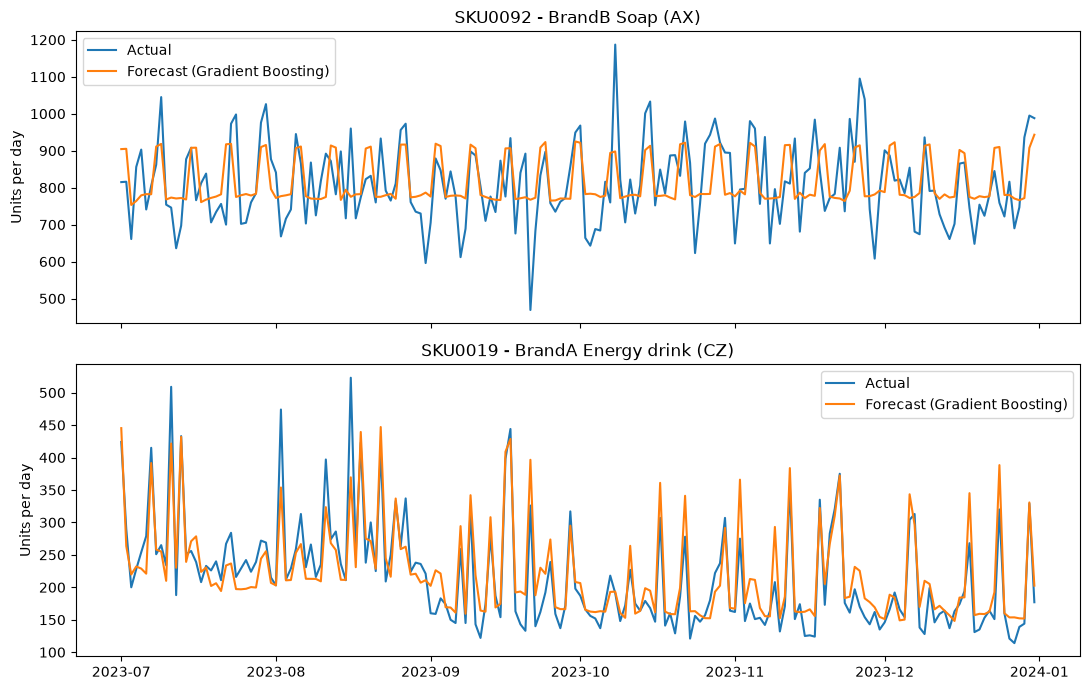

In [85]:
# Actual vs forecast: one stable SKU (AX) and one erratic SKU (CZ), daily totals over all stores
ax_sku = sku_labels[sku_labels["segment"] == "AX"].index[0]
cz_sku = sku_labels[sku_labels["segment"] == "CZ"].index[0]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, sku in zip(axes, [ax_sku, cz_sku]):
    daily = test_results[test_results["sku_id"] == sku].groupby("date")[["units_sold", best_model]].sum()
    ax.plot(daily.index, daily["units_sold"], label="Actual")
    ax.plot(daily.index, daily[best_model], label="Forecast (" + best_model + ")")
    ax.set_title(sku + " - " + sku_labels.loc[sku, "sku_name"] + " (" + sku_labels.loc[sku, "segment"] + ")")
    ax.set_ylabel("Units per day")
    ax.legend()
plt.tight_layout()
plt.show()

In [86]:
# Does adding up the stores make the forecast better? Compare store-level and SKU-level (all stores added up) accuracy
sku_day = test_results.groupby(["sku_id", "date"])[["units_sold", best_model]].sum().reset_index()

comparison = pd.DataFrame({
    "store-SKU-day level": get_metrics(test_results["units_sold"].values, test_results[best_model].values),
    "SKU-day level (all stores)": get_metrics(sku_day["units_sold"].values, sku_day[best_model].values),
}).T.round(2)
comparison

,MAE,RMSE,MAPE_%
store-SKU-day level,16.82,26.39,52.57
SKU-day level (all stores),57.10,83.01,9.69


### 5. Stockout prediction (classification)
Here the target is `stock_out_flag` (1 = stockout on that day, 0 = no stockout). Stockouts are rare (about 3% of days), so a model that always says "no stockout" would be right 97% of the time but useless. That is why the guide asks for **precision, recall and F1** instead of accuracy:
* **Precision:** of the days I flag as stockouts, how many really were?
* **Recall:** of the real stockouts, how many did I catch?
* **F1:** a single score that combines precision and recall.

I used `class_weight="balanced"` so the model gives extra weight to the rare stockout days. The inputs are all known the day before: lagged sales, yesterday's stock level and stockout, lead time, promotion, and calendar.

In [87]:
stockout_cols = (["lag_1", "lag_7", "rolling_mean_7", "lag_stockout_1", "soh_lag_1", "lead_time_days",
                  "on_promo", "promo_discount", "is_holiday", "is_weekend", "day_of_week", "month"] + channel_cols)

stockout_train = train_scaled["stock_out_flag"].values
stockout_test = test_scaled["stock_out_flag"].values
print("Share of stockout days - training:", round(stockout_train.mean(), 4), "| test:", round(stockout_test.mean(), 4))

clf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=50,
                             class_weight="balanced", random_state=42, n_jobs=-1)
clf.fit(train_scaled[stockout_cols], stockout_train)

stockout_pred = clf.predict(test_scaled[stockout_cols])
stockout_prob = clf.predict_proba(test_scaled[stockout_cols])[:, 1]

Share of stockout days - training: 0.0306 | test: 0.0305


In [88]:
# Confusion table: rows = what really happened, columns = what the model predicted
pd.crosstab(pd.Series(stockout_test, name="Actual"), pd.Series(stockout_pred, name="Predicted"))

Predicted,0,1
Actual,,
0,11920,6097
1,374,193


In [89]:
# Two reference points: random flags (flagging the same share of days at random) and "never predict a stockout"
rng = np.random.RandomState(42)
random_flags = (rng.rand(len(stockout_test)) < stockout_pred.mean()).astype(int)
never_flags = np.zeros(len(stockout_test), dtype=int)

def class_scores(y_true, y_pred):
    return {"Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "Share flagged": y_pred.mean()}

class_table = pd.DataFrame({
    "Random Forest classifier": class_scores(stockout_test, stockout_pred),
    "Random flags": class_scores(stockout_test, random_flags),
    "Never predict a stockout": class_scores(stockout_test, never_flags),
}).T.round(3)
print(class_table)

# ROC AUC: 0.5 means no better than chance, 1.0 is perfect
print("ROC AUC of the classifier:", round(roc_auc_score(stockout_test, stockout_prob), 3))

                          Precision  Recall     F1  Share flagged
Random Forest classifier      0.031   0.340  0.056          0.338
Random flags                  0.032   0.351  0.058          0.338
Never predict a stockout      0.000   0.000  0.000          0.000
ROC AUC of the classifier: 0.499


In [90]:
# Is any single factor linked to stockouts? Stockout rate for different conditions in the training data
print("Stockout rate on promotion days     :", round(train_scaled.loc[train_scaled["on_promo"] == 1, "stock_out_flag"].mean(), 4))
print("Stockout rate on non-promotion days :", round(train_scaled.loc[train_scaled["on_promo"] == 0, "stock_out_flag"].mean(), 4))
print("Stockout rate on holidays           :", round(train_scaled.loc[train_scaled["is_holiday"] == 1, "stock_out_flag"].mean(), 4))
print("Stockout rate on other days         :", round(train_scaled.loc[train_scaled["is_holiday"] == 0, "stock_out_flag"].mean(), 4))
print("Stockout rate after a stockout day  :", round(train_scaled.loc[train_scaled["lag_stockout_1"] == 1, "stock_out_flag"].mean(), 4))

Stockout rate on promotion days     : 0.0318
Stockout rate on non-promotion days : 0.0304
Stockout rate on holidays           : 0.0315
Stockout rate on other days         : 0.0305
Stockout rate after a stockout day  : 0.0269


**How to read this:** compare the classifier with the random flags. If their precision and recall are about the same, and the AUC is close to 0.5, the model has learned nothing useful about stockouts. The last cell shows why: the stockout rate hardly changes with any of the conditions.

### 6. Save the results for Step 6

In [91]:
import joblib
test_results.to_csv("data/processed/test_predictions.csv.gz", index=False, compression="gzip")
joblib.dump(rf_reg, "data/processed/rf_regressor.joblib")
print("Saved:", test_results.shape)

Saved: (18584, 12)


# Step 6: Explainability, Ethics and Impact

What I want to find out:
1. Which features drive the forecast: momentum (lags) or promotions? (feature importance)
2. Does the model treat all channels fairly, or does it under-forecast some of them? (bias check)
3. What do the better forecasts mean for the business? (safety stock)

In [92]:
# Extra library for Step 6
from sklearn.inspection import permutation_importance

### 1. Feature importance
A Random Forest reports how much each feature helped to reduce the error across all its trees. The importances add up to 1. A higher value means the model relies more on that feature.

rolling_mean_7         0.747
list_price             0.069
on_promo               0.046
promo_discount         0.041
channel_Hypermarket    0.016
month                  0.013
day_of_week            0.012
is_weekend             0.011
country_code           0.009
lag_30                 0.007
lag_7                  0.007
lag_1                  0.006
dtype: float64


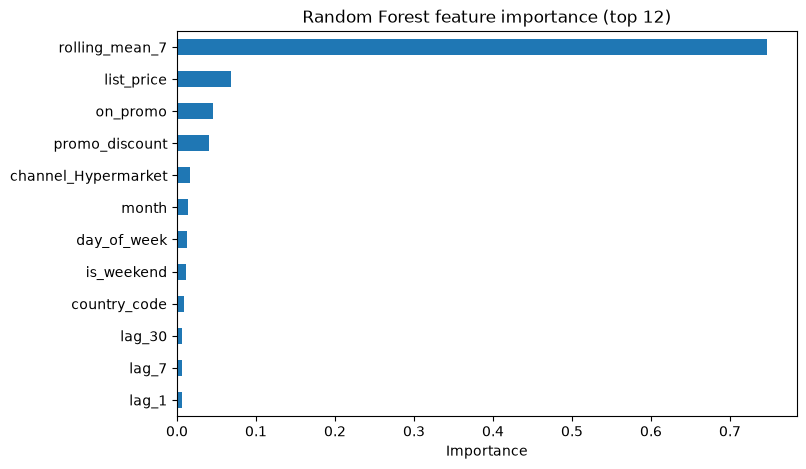

In [93]:
# The feature names are stored inside the fitted model
feature_cols = list(rf_reg.feature_names_in_)

importance = pd.Series(rf_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importance.round(3).head(12))

# Bar chart of the 12 most important features (reversed so the biggest is at the top)
plt.figure(figsize=(8, 5))
importance.head(12)[::-1].plot(kind="barh")
plt.title("Random Forest feature importance (top 12)")
plt.xlabel("Importance")
plt.show()

To answer "momentum or promotions?", I added up the importance of the features in each group.

Momentum (lags and rolling mean)    0.767
Promotion                           0.087
Product (list price)                0.069
Location and channel                0.040
Calendar                            0.037
dtype: float64
Total: 1.0


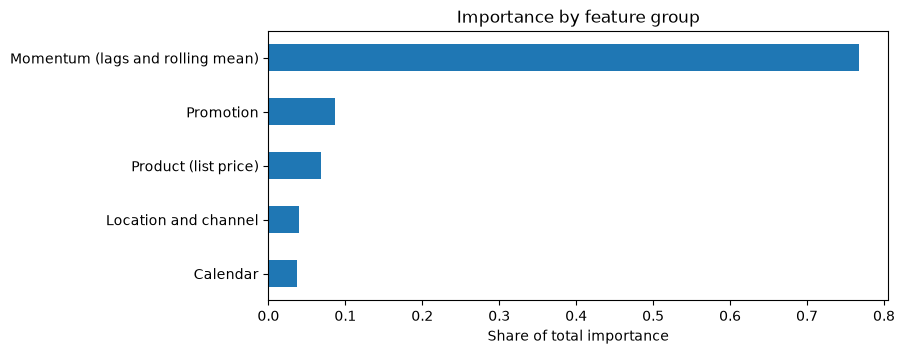

In [94]:
channel_cols = [c for c in feature_cols if c.startswith("channel_")]

feature_groups = {
    "Momentum (lags and rolling mean)": ["lag_1", "lag_7", "lag_30", "rolling_mean_7"],
    "Promotion": ["on_promo", "promo_discount"],
    "Calendar": ["is_weekend", "is_holiday", "is_month_start", "is_month_end", "day_of_week", "month"],
    "Product (list price)": ["list_price"],
    "Location and channel": ["country_code", "city_code"] + channel_cols,
}

group_importance = {}
for group_name, cols in feature_groups.items():
    group_importance[group_name] = importance[cols].sum()

group_importance = pd.Series(group_importance).sort_values(ascending=False)
print(group_importance.round(3))
print("Total:", round(group_importance.sum(), 3))

plt.figure(figsize=(8, 3.5))
group_importance[::-1].plot(kind="barh")
plt.title("Importance by feature group")
plt.xlabel("Share of total importance")
plt.show()

#### Cross-check with permutation importance
The built-in importance can favour some kinds of features. A second method is **permutation importance**: shuffle one feature at a time in the test data and see how much the forecast error grows. A feature that matters causes a big rise in error when shuffled.

In [95]:
# Use a random sample of 10,000 test rows to keep it fast
sample = test_scaled.sample(10000, random_state=42)

perm = permutation_importance(rf_reg, sample[feature_cols], sample["units_sold"],
                              n_repeats=3, random_state=42, scoring="neg_mean_absolute_error", n_jobs=-1)

perm_importance = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)
print("Increase in MAE (units) when the feature is shuffled:")
print(perm_importance.round(3).head(10))

Increase in MAE (units) when the feature is shuffled:
rolling_mean_7         25.294
list_price              2.714
channel_Hypermarket     1.625
promo_discount          1.324
on_promo                1.276
month                   0.655
channel_E-commerce      0.444
city_code               0.256
channel_Supermarket     0.246
is_weekend              0.211
dtype: float64


### 2. Bias check: is any channel treated unfairly?
The guide warns that a model must not systematically under-allocate stock to small local retailers in favour of big modern outlets. This dataset has no Traditional Trade channel, so the closest comparison is between the **Convenience** (small-format) and **E-commerce** channels and the large **Hypermarket** and **Supermarket** channels.

Two measures, using the best machine learning model:
* **Bias %** = (total forecast - total actual) / total actual. A *negative* value means the model under-forecasts that channel, so it would receive too little stock.
* **Under-forecast share:** the share of days when the forecast was below actual sales. A high share means more days at risk of a stockout.

In [96]:
# Best of the machine learning models (lowest MAE)
ml_models = ["Linear Regression", "Random Forest", "Gradient Boosting"]
mae_by_model = {}
for m in ml_models:
    mae_by_model[m] = (test_results[m] - test_results["units_sold"]).abs().mean()
best_model = min(mae_by_model, key=mae_by_model.get)
print("Best model:", best_model)

test_results["forecast"] = test_results[best_model]
test_results["abs_error"] = (test_results["forecast"] - test_results["units_sold"]).abs()
test_results["under_forecast"] = (test_results["forecast"] < test_results["units_sold"]).astype(int)

Best model: Gradient Boosting


In [97]:
def bias_table(group_col):
    table = test_results.groupby(group_col).agg(
        rows=("units_sold", "size"),
        actual_units=("units_sold", "sum"),
        forecast_units=("forecast", "sum"),
        mae=("abs_error", "mean"),
        avg_demand=("units_sold", "mean"),
        under_forecast_share=("under_forecast", "mean"),
    )
    table["bias_%"] = (table["forecast_units"] - table["actual_units"]) / table["actual_units"] * 100
    table["mae_%_of_demand"] = table["mae"] / table["avg_demand"] * 100
    return table[["rows", "avg_demand", "mae", "mae_%_of_demand", "bias_%", "under_forecast_share"]].round(3)

by_channel = bias_table("channel")
by_channel

,rows,avg_demand,mae,mae_%_of_demand,bias_%,under_forecast_share
channel,,,,,,
Convenience,1104,31.716,8.387,26.445,1.452,0.483
E-commerce,4416,66.941,18.116,27.063,0.656,0.507
Hypermarket,8648,71.274,19.246,27.003,-0.032,0.512
Supermarket,4416,49.569,12.889,26.003,-0.458,0.512


In [98]:
by_country = bias_table("country")
by_country

,rows,avg_demand,mae,mae_%_of_demand,bias_%,under_forecast_share
country,,,,,,
Austria,1472,78.921,21.369,27.076,0.920,0.516
France,1472,71.315,18.442,25.860,-1.819,0.529
Germany,3312,74.391,20.158,27.098,0.393,0.506
Italy,5704,54.667,14.551,26.617,-0.172,0.514
Netherlands,1104,31.716,8.387,26.445,1.452,0.483
Poland,1288,61.772,16.779,27.164,-0.164,0.509
Spain,4232,64.265,17.341,26.983,0.470,0.503


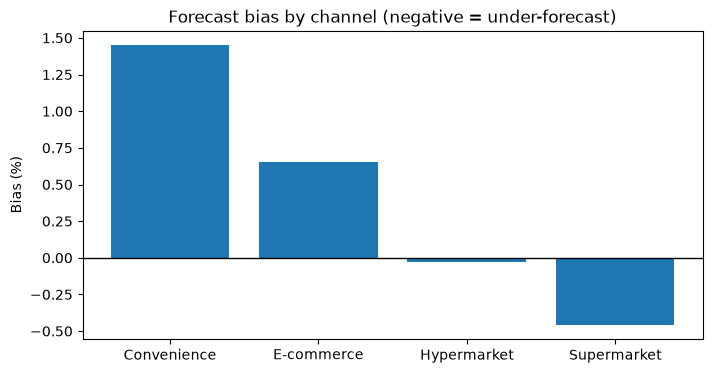

In [99]:
# Chart: forecast bias by channel (below zero = under-forecast)
plt.figure(figsize=(8, 4))
plt.bar(by_channel.index, by_channel["bias_%"])
plt.axhline(0, color="black", linewidth=1)
plt.title("Forecast bias by channel (negative = under-forecast)")
plt.ylabel("Bias (%)")
plt.show()

**How to read this:** compare the small-format and online channels with the large ones. If Convenience or E-commerce had a clearly more negative bias or a higher under-forecast share, the model would systematically give them less stock, which is the unfair outcome the guide warns about. Small differences close to zero mean no sign of systematic bias in this dataset.

### 3. Business impact: safety stock
**Safety stock** is the extra inventory held to protect against forecast errors during the replenishment lead time:

**Safety stock = z x forecast error (RMSE) x square root of lead time**

* **z** depends on the service level I want. For 95%, z = 1.645.
* **RMSE** is the typical size of the forecast error per day.
* **Lead time** is how many days it takes to replenish.

Smaller forecast errors mean less safety stock for the same service level. I calculated it for each store-SKU series, then added them up for each model.

*Assumptions: daily errors are independent and roughly normal.*

In [100]:
z = stats.norm.ppf(0.95)          # z-value for a 95% service level
print("z =", round(z, 3))

models_to_compare = ["Naive (same day last week)", "Linear Regression", "Random Forest", "Gradient Boosting"]

safety_rows = []
for model_name in models_to_compare:
    test_results["sq_error"] = (test_results[model_name] - test_results["units_sold"]) ** 2

    # For each store-SKU series: RMSE of the forecast errors and the average lead time
    per_series = test_results.groupby(["store_id", "sku_id"]).agg(
        rmse=("sq_error", lambda x: np.sqrt(x.mean())),
        lead_time=("lead_time_days", "mean"),
    )
    per_series["safety_stock"] = z * per_series["rmse"] * np.sqrt(per_series["lead_time"])
    safety_rows.append({"model": model_name, "total_safety_stock_units": per_series["safety_stock"].sum()})

safety = pd.DataFrame(safety_rows).set_index("model")

# How much less safety stock than the Linear Regression baseline?
baseline = safety.loc["Linear Regression", "total_safety_stock_units"]
safety["change_vs_linear_regression_%"] = (safety["total_safety_stock_units"] / baseline - 1) * 100
safety.round(1)

z = 1.645


,total_safety_stock_units,change_vs_linear_regression_%
model,,
Naive (same day last week),14761.6,36.9
Linear Regression,10783.1,0.0
Random Forest,9390.7,-12.9
Gradient Boosting,9375.2,-13.1


### 4. Ethical considerations
* **Fairness between channels:** under-forecasting a small-format or online channel means less stock allocated to it and more stockouts for its customers. The bias check above is how I monitor this, and it should be repeated whenever the model is updated.
* **Community impact:** in the guide's context (small local retailers in Africa), a stockout is not just lost revenue, it can affect access to food and essential goods. This dataset has no Traditional Trade channel, so I can only use Convenience as an approximate stand-in, and I should say so openly.
* **Demand versus sales:** the model learns from sales, not demand. On stockout days sales are lower than real demand, so a channel that often runs out of stock looks like it has lower demand, and may then get even less stock. This feedback loop is a real risk.
* **Stockouts are not predictable here:** the stockout classifier was no better than random, so it should not be used to make allocation decisions.
* **Transparency:** feature importance lets planners see what drives the forecast, which supports buy-in for sales and operations planning.

### Recommendations for sales and operations planning (S&OP)
##### What does the feature importance say about how planners should use recent sales and promotion plans?
Recent sales dominate. Momentum features carry 76.7% of impurity importance, and the 7-day rolling mean alone is 74.7%. Permutation importance confirms it: shuffling the rolling mean raises MAE by about 25 units against a baseline of 16.8. Planners should anchor on a frequently refreshed recent-sales baseline. Promotion features add 8.7% and should be applied as an overlay for the promoted SKUs (Z segments and CY), not as the main driver.

##### Where does the best model help most, and for which SKU types is the error still large?
It helps most against the naive benchmark (MAE −36.9%) and at aggregate level: SKU-day MAPE is 9.7% against 52.6% at store-SKU-day. Error is still large in absolute units for high-volume SKUs (SKU0035 MAE 34.25, SKU0099 27.77). In relative terms it is about 26–28% of demand for every SKU, with the highest MAPE on the two BY SKUs (61.9% and 57.8%), which were also the non-stationary ones. Plan at SKU level across stores and treat store-level forecasts as indicative.

##### How much safety stock could be saved at the same service level?
At a 95% service level (z = 1.645), Gradient Boosting needs 9,375 units of safety stock against 10,783 for Linear Regression and 14,762 for the naive forecast. That is a saving of about 13% vs Linear Regression and about 36% vs naive. Random Forest is almost identical (9,391), so the gain comes from the tree-based approach. Assumes independent, roughly normal daily errors.

##### What should be monitored regularly (bias by channel, forecast error by SKU)?
Forecast bias and under-forecast share by channel and country (currently within ±2% and 48–53%), and MAE as a share of demand by SKU (currently about 26–28%, higher for the BY SKUs). Suggested alert levels are in section C and should be confirmed with your supervisor. Repeat the bias check whenever the model is retrained, and re-run the ADF test on each refresh

##### What data would make stockout prediction possible?
The classifier’s AUC of 0.499 and flat stockout rates (about 3% under every condition) show that current features carry no stockout signal. Useful additions would be inbound shipment and purchase-order data, supplier delivery performance against promised lead time, unconstrained demand (sales corrected for stockout days), and finer stock-on-hand and replenishment records. Until then the classifier should not be used for allocation.
